# Análisis Exploratorio de Datos — Jujuy (junio - agosto 2023)

**Objetivo**: describir la distribución de los eventos de protesta registrados en Jujuy durante el período junio-agosto de 2023, con foco en actores, demandas, repertorios y respuesta estatal.

**Fuente**: base propia de eventos codificados a partir de noticias locales.

**Autor**: Federico Nicolás Llanes

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_excel("../data/processed/eventos_chubut_jujuy.xlsx")
df_jujuy = df[df["provincia"] == "Jujuy"].copy()

print(f"Jujuy: {len(df_jujuy)} eventos")

Jujuy: 66 eventos


## Panorama general

Se realiza un análisis descriptivo de la base filtrada a Jujuy. El objetivo es verificar la cobertura temporal, la concentración geográfica y la distribución del repertorio de protesta en el período.

#### Concentración por localidad

In [2]:
print(f"Total de eventos: {len(df_jujuy)}\n")

print("=== Top 10 localidades ===")
print(df_jujuy["localidad"].value_counts().head(10))

Total de eventos: 66

=== Top 10 localidades ===
localidad
San Salvador de Jujuy            34
Varias localidades               19
Libertador General San Martín     2
Tilcara                           2
Abra Pampa                        1
Purmamarca                        1
San Pedro de Jujuy                1
Ruta (sin localidad puntual)      1
Sin datos                         1
Finca El Pongo                    1
Name: count, dtype: int64


La distribución por localidad muestra una fuerte concentracion en San Salvador de Jujuy (34 eventos, 52% del total). Esta centralidad es consistente con el hecho de que la capital provincial fue el epicentro del conflicto por la reforma constitucional, sede del gobierno y lugar donde se concentraron las movilizaciones.

Un dato relevante es la categoria 'varias localidades' (19 eventos, 29%) casí un tercio de los eventos no se registran en una localidad puntual sino como acciones simultáneas en múltiples puntos de la provincia. Esto sugiere una estructura federal del conflicto

El resto de las localidades aparece con presencia marginal: Libertador General San Martin (2), Tilcara (2) y el resto de localidades con un solo evento.

#### Cobertura temporal

In [4]:
df_jujuy["noticia_id"] = df_jujuy["noticia_id"].astype(str)

df_jujuy["anio"] = df_jujuy["noticia_id"].str[:4]
df_jujuy["mes"] = df_jujuy["noticia_id"].str[:6]
df_jujuy["dia"] = df_jujuy["noticia_id"].str[:8]
df_jujuy["anio_mes"] = df_jujuy["noticia_id"].str[:6]

df_jujuy = df_jujuy[df_jujuy["provincia"] == "Jujuy"].copy()
print(df_jujuy["mes"].value_counts().sort_index())

mes
202306    40
202307    21
202308     5
Name: count, dtype: int64


Los eventos se distribuyen de forma decreciente a lo largo del período: Junio concentra 40 eventos, julio desiende a 21 y agosto cae a 5. El patron es coherente con el ciclo del conflicto: la reforma constitucional se sancionó el 15 de Junio de 2023, lo que activó las protestas más masivas durante este mes.

#### Serie diaria y pico

In [27]:
df_jujuy["fecha_str"] = df_jujuy["noticia_id"].str.replace(r"\D", "", regex=True).str[:8]
df_jujuy["fecha"] = pd.to_datetime(df_jujuy["fecha_str"], format="%Y%m%d", errors="coerce")

print(f"Fechas inválidas: {df_jujuy['fecha'].isna().sum()}")

por_dia_jujuy = df_jujuy.groupby("fecha").size()
print(f"\nDías con eventos: {len(por_dia_jujuy)}")
print(f"Rango: {por_dia_jujuy.index.min()} a {por_dia_jujuy.index.max()}")

dia_pico = por_dia_jujuy.idxmax()
n_pico = por_dia_jujuy.max()
print(f"\nPico: {dia_pico.strftime('%d/%m/%Y')} con {n_pico} eventos")

print("\n=== Top 5 días con más eventos ===")
print(por_dia_jujuy.sort_values(ascending=False).head(5))

Fechas inválidas: 0

Días con eventos: 40
Rango: 2023-06-03 00:00:00 a 2023-08-10 00:00:00

Pico: 13/06/2023 con 6 eventos

=== Top 5 días con más eventos ===
fecha
2023-06-13    6
2023-06-15    3
2023-06-27    3
2023-06-21    3
2023-06-17    2
dtype: int64


La serie diaria muestra 40 días con eventos sobre un total de 69 días del período analizado. El pico se registra el 13 de junio de 2023 con 6 eventos, seguido por varios días con 2-3 eventos (15/06, 17/06, 21/06, 27/06).

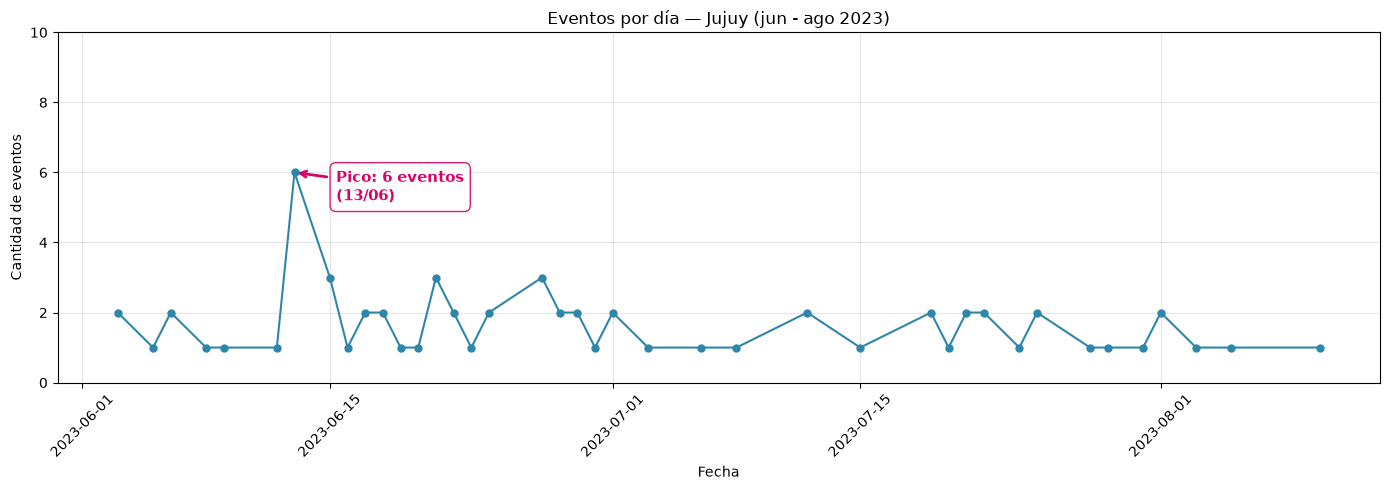

In [6]:
fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(por_dia_jujuy.index, por_dia_jujuy.values, marker="o",
        markersize=5, linewidth=1.5, color="#2E86AB")

ax.annotate(f"Pico: {n_pico} eventos\n({dia_pico.strftime('%d/%m')})",
            xy=(dia_pico, n_pico),
            xytext=(30, -20), textcoords="offset points",
            fontsize=11, color="#D90368", fontweight="bold",
            arrowprops=dict(arrowstyle="->", color="#D90368", lw=2),
            bbox=dict(boxstyle="round,pad=0.4", facecolor="white",
                      edgecolor="#D90368", alpha=0.9))

ax.set_ylim(0, n_pico + 4)
ax.set_title("Eventos por día — Jujuy (jun - ago 2023)")
ax.set_xlabel("Fecha")
ax.set_ylabel("Cantidad de eventos")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

El 13 de junio se ubica dos días antes de la sanción de la reforma constitucional provincial, y coincide con el momento de mayor movilización docente contra el paquete de reformas. La ausencia de un pico único más marcado  sugiere una conflictividad más distribuida en el tiempo, con varios momentos de alta actividad en lugar de un único estallido

In [7]:
dia_pico_str = dia_pico.strftime("%Y%m%d")  # ej: "20211216"

noticias_pico = df_jujuy[df_jujuy["fecha"] == dia_pico]

# Mostrar columnas clave
cols_ver = ["noticia_id", "localidad", "tipo_accion", "actores_participantes", "demanda_principal"]
print(f"=== Noticias del {dia_pico.strftime('%d/%m/%Y')} ({len(noticias_pico)} eventos) ===\n")
print(noticias_pico[cols_ver].to_string(index=False))

=== Noticias del 13/06/2023 (6 eventos) ===

noticia_id                     localidad tipo_accion       actores_participantes                                        demanda_principal
2023061301         San Salvador de Jujuy      Marcha           Docentes/Gremios                                                 Salarial 
2023061302         San Salvador de Jujuy        Otra           Docentes/Gremios                                 Salarial / Contra Reforma
2023061303            Varias localidades      Marcha           Docentes/Gremios                                 Salarial / Contra Reforma
2023061304            Varias localidades       Mixta docentes, gremios estatales mejoras salariales y rechazo a la reforma constitucional
2023061305            Varias localidades        Otra     docentes (Adep, Cedems) mejoras salariales y rechazo a la reforma constitucional
2023061306 Libertador General San Martín      Marcha  docentes y gremios locales mejoras salariales y rechazo a la reforma cons

Los 6 eventos del 13/06 comparten un eje común: todos involucran a docentes y gremios estatales, y todos combinan demandas salariales con rechazo a la reforma constitucional. Los eventos se distribuyen entre San Salvador de Jujuy, "Varias localidades" y Libertador General San Martín.

El patrón revela la articulación del conflicto jujeño: no se trata de una protesta aislada sino de una acción coordinada multisectorial, con docentes como núcleo movilizador y gremios estatales como aliados. La coincidencia de demandas salariales y político-legales en un mismo evento es un rasgo distintivo de Jujuy: mientras en Chubut las demandas ambientales y salariales tendían a aparecer en eventos separados, en Jujuy se articulan en una misma movilización.

## Análisis de acciones, actores y demandas principales

##### Tipos de acciones

In [8]:
print("=== Tipo de acción ===")
print(df_jujuy["tipo_accion"].value_counts())

=== Tipo de acción ===
tipo_accion
Marcha    30
Corte     14
Mixta     12
Otra       9
Acampe     1
Name: count, dtype: int64


El repertorio de jujuy esta fuertemente concentrado en torno a marchas (30 eventos) y cortes (14) mostrando una estructura binaría. Por un lado, movilizaciones masivas (marchas) y por el otro lado acciones disruptivas (cortes)

El corte de la ruta es especialmente relevante en el contexto jujeño porque la reforma constitucional provincial buscaba penalizarlo explícitamente. Cada corte por lo tanto se lo puede interpretar no solo como una acción de protesta sino también un desafío directo al marco legal que el gobierno trataba de imponer

Los eventos mixtos (12) y otras acciones (12) conforman el resto del repertorio el cual sera desglozado a continuacion

Pero antes se desglozara los eventos en los que la forma de protesta fueron los cortes

In [32]:
df_jujuy[df_jujuy["tipo_accion"] == "Corte"][["noticia_id", "tipo_accion","tipo_accion_detalle","demanda_principal"]]

,noticia_id,tipo_accion,tipo_accion_detalle,demanda_principal
140,2023061702,Corte,corte de ruta,Contra Reforma
141,2023061801,Corte,Corte total de ruta sostenido desde la noche d...,Rechazo a la reforma constitucional (disposici...
142,2023061807,Corte,"Intento de corte de la ruta 34, impedido por l...","Rechazo a la reforma constitucional, en el mar..."
143,2023061901,Corte,corte de ruta,rechazar la reforma parcial de la Constitución
149,2023062202,Corte,corte de ruta,sin datos
152,2023062402,Corte,corte de ruta,Contra Reforma / Contra la megaminería
153,2023062701,Corte,corte de ruta,sin datos
155,2023062703,Corte,corte de ruta,sin datos
156,2023062801,Corte,Corte de ruta,rechazo a la reforma constitucional y mejoras ...
159,2023062902,Corte,corte de ruta,sin datos


El desgloze de las protestas expresadas con corte confirma que en general los reclamos se vinculaban con el rechazo a la reforma consitucional

In [28]:
df_jujuy[df_jujuy["tipo_accion"] == "Mixta"][["noticia_id", "tipo_accion","tipo_accion_detalle","demanda_principal"]]

,noticia_id,tipo_accion,tipo_accion_detalle,demanda_principal
124,2023060601,Mixta,Movilización Mixta,Salarial | mejoras salariales
127,2023060901,Mixta,movilización mixta (paro + marcha + marcha de ...,mejoras salariales
128,2023061201,Mixta,movilización mixta (paro + marcha),mejoras salariales y rechazo a la reforma cons...
132,2023061304,Mixta,movilización mixta (paro + marcha),mejoras salariales y rechazo a la reforma cons...
136,2023061502,Mixta,movilización mixta,mejoras salariales
147,2023062103,Mixta,Movilización Mixta,rechazo a la represión del 20/6 y a la reforma...
154,2023062702,Mixta,marcha / paro junto con la marcha,Salarial/ Contra Reforma
168,2023071501,Mixta,marcha / paro,Contra las detenciones/ Salarial/ Contra la re...
172,2023072001,Mixta,marcha / paro,Pedido de elementos de higiene y seguridad
181,2023073101,Mixta,Movilización Mixta,definición sobre continuidad o suspensión del ...


El desgloce de las acciones mixtas combina en general movilizacion y paro y por lo general suele abarcar protestas relacionadas a los salarios y a las protestas contra la reforma 

In [31]:
df_jujuy[df_jujuy["tipo_accion"] == "Otra"][["noticia_id", "tipo_accion","tipo_accion_detalle","demanda_principal"]]

,noticia_id,tipo_accion,tipo_accion_detalle,demanda_principal
122,2023060302,Otra,Asamblea sindical + emplazamiento a la empresa...,Recomposición salarial: piden $280.000 para la...
123,2023060501,Otra,Medidas de fuerza de gremios estatales y la CT...,Rechazo al articulo de la reforma constitucion...
125,2023060602,Otra,paro por tiempo indefinido,Salarial | mejoras salariales
126,2023060801,Otra,paro por tiempo indefinido,Salarial | mejoras salariales
130,2023061302,Otra,paro / paro por tiempo indeterminado,Salarial / Contra Reforma
133,2023061305,Otra,paro por tiempo indeterminado,mejoras salariales y rechazo a la reforma cons...
148,2023062201,Otra,paro / paro docente por tiempo indeterminado,Salarial / Contra Reforma
167,2023071202,Otra,asamblea,rechazo a la reforma constitucional y defensa ...
173,2023072101,Otra,paro,mejores condiciones laborales (cumplimiento de...


El desgloce de las acciones 'otras' detalla en general paros y paros por tiempo indeterminado y por lo general suele comprender protestas salariales y en algunos casos protestas contra la reforma 

##### Actores participantes

In [9]:
COLS_ACTORES = ["docentes", "gremios_estatales", "sindicatos_privados",
                "organizaciones_sociales", "comunidades_indigenas", "vecinos",
                "colectivos_ambientales", "colectivos_especificos",
                "partidos_politicos", "policias_actores",
                "publico_general", "colectivos_violentos", "otros"]

print("=== Actores (n eventos) ===")
print(df_jujuy[COLS_ACTORES].sum().sort_values(ascending=False))

=== Actores (n eventos) ===
docentes                   41
organizaciones_sociales    20
comunidades_indigenas      18
gremios_estatales          13
vecinos                    11
sindicatos_privados         5
publico_general             5
colectivos_especificos      3
partidos_politicos          1
colectivos_ambientales      0
policias_actores            0
colectivos_violentos        0
otros                       0
dtype: int64


La distribucion de los actores muetra el siguiente patron:

- Los docentes (41 eventos) son el actor hegemonico. Durante el desarrollo del marco de la reforma constitucional los docentes ademas de reclaramar contra la reforma judicial realizaban reclamos en el marco salarial
- Las organizaciones sociales (20 eventos) aparacen como el segundo actor importante
- las comunidades de los pueblos originarios aparece como tercer actor importante, su presencia se vincula al conflicto territorial y a la defensa de derechos especificos frente a la reforma

In [34]:
df_jujuy[df_jujuy["comunidades_indigenas"] == 1][["noticia_id", "actores_participantes", "demanda_principal"]]

,noticia_id,actores_participantes,demanda_principal
121,2023060301,Partidos políticos/Multisectorial de mujere/Co...,"respeto de los derechos de las mujeres, emerge..."
139,2023061701,Docentes/Gremios/Comunidades indígenas,Salarial / Contra Reforma
140,2023061702,Organizaciones sociales/Gremios/Comunidad indí...,Contra Reforma
141,2023061801,"Comunidades originarias, organizaciones social...",Rechazo a la reforma constitucional (disposici...
142,2023061807,Integrantes de pueblos originarios,"Rechazo a la reforma constitucional, en el mar..."
143,2023061901,"comunidades orginiarias, organizaciones social...",rechazar la reforma parcial de la Constitución
144,2023062001,Comunidad educativa,Salarial
145,2023062101,"docentes, comunidades indígenas, trabajadores ...",rechazar la reforma parcial de la Constitución
146,2023062102,Agrupaciones partidarias/Gremios docentes/Mine...,Contra Reforma/Contra Represión
148,2023062201,Gremios/Comunidades indígenas/Mineros autoconv...,Salarial / Contra Reforma


In [35]:
df_jujuy[df_jujuy["organizaciones_sociales"] == 1][["noticia_id", "actores_participantes", "demanda_principal"]]

,noticia_id,actores_participantes,demanda_principal
121,2023060301,Partidos políticos/Multisectorial de mujere/Co...,"respeto de los derechos de las mujeres, emerge..."
135,2023061501,Docentes/Gremios/ Organizaciones sociales,Salarial / Contra Reforma
137,2023061503,Docentes/Gremios/ Organizaciones sociales,Salarial / Contra Reforma
140,2023061702,Organizaciones sociales/Gremios/Comunidad indí...,Contra Reforma
141,2023061801,"Comunidades originarias, organizaciones social...",Rechazo a la reforma constitucional (disposici...
143,2023061901,"comunidades orginiarias, organizaciones social...",rechazar la reforma parcial de la Constitución
149,2023062202,Piqueteros,sin datos
155,2023062703,Piqueteros,sin datos
156,2023062801,"docentes, gremios, organizaciones sociales, 34...",rechazo a la reforma constitucional y mejoras ...
159,2023062902,Piqueteros,sin datos


El desglose de los eventos con participación de organizaciones sociales muestra dos patrones diferenciados:

1. **Organizaciones sociales articuladas con docentes y comunidades originarias** (junio y julio): los eventos combinan demandas salariales, rechazo a la reforma y reivindicaciones territoriales. La categoría "Multisectorial" aparece en varias noticias, indicando la existencia de un espacio de coordinación entre sectores.

2. **Piqueteros autónomos** (22/06, 27/06, 29/06, 22/07): eventos con demandas registradas como "sin datos", lo que sugiere acciones cuyo objetivo específico no quedó claro en la cobertura periodística, probablemente por tratarse de cortes prolongados sin una demanda explícita única.

La combinación de "organizaciones sociales + comunidades indígenas + docentes" en varios eventos (especialmente en junio) configura la alianza más característica del conflicto jujeño.

#### Cantidad de actores por evento

In [12]:
df_jujuy["n_actores"] = df_jujuy[COLS_ACTORES].sum(axis=1)
print("=== Cantidad de actores por evento ===")
print(df_jujuy["n_actores"].value_counts().sort_index())

=== Cantidad de actores por evento ===
n_actores
1    36
2    15
3    10
4     4
5     1
Name: count, dtype: int64


La distribucion muesta un patron articulado:

- 1 actor: 36 eventos
- 2 actores: 15 eventos
- 3 actores o mas: 15 eventos

Aunque la mayoria de los eventos tienen un solo actor, casi la mitad de los eventos involucran a dos o mas actores.
La presencia de un tercio de eventos con 3 o más actores confirma la existencia de un espacio multisectorial activo en Jujuy.

#### Demandas

In [13]:
COLS_DEMANDAS = ["demanda_salarial", "demanda_laboral", "demanda_ambiental_territorial",
                 "demanda_politica_legal", "demanda_ddhh", "demanda_servicios",
                 "demanda_derechos_especificos", "demanda_institucional",
                 "demanda_conmemoracion"]

print("=== Demandas (n eventos) ===")
print(df_jujuy[COLS_DEMANDAS].sum().sort_values(ascending=False))

=== Demandas (n eventos) ===
demanda_salarial                 39
demanda_politica_legal           39
demanda_ddhh                      8
demanda_laboral                   3
demanda_derechos_especificos      3
demanda_conmemoracion             3
demanda_ambiental_territorial     2
demanda_institucional             1
demanda_servicios                 0
dtype: int64


El patrón de demandas muestra una estructura **bipolar**: dos demandas empatan en el primer lugar:

- **Demanda salarial** (39 eventos, 59%)
- **Demanda política-legal** (39 eventos, 59%)

El conflicto jujeño estuvo atravesado por la articulación entre reclamos laborales sectoriales (salarios docentes, condiciones de trabajo) y un eje político-institucional (rechazo a la reforma constitucional, criminalización de la protesta).

En un segundo nivel aparecen:
- **DDHH** (8 eventos, 12%): vinculada a las detenciones y a la conmemoración del Apagón del Terror (julio).
- **Laboral** (3), **derechos específicos** (3), **conmemoración** (3): demandas puntuales.
- **Ambiental-territorial** (2): presencia marginal, a diferencia de Chubut donde era el eje central.
- **Institucional** (1) y **servicios** (0): prácticamente ausentes.

#### Cantidad de demandas por evento

In [14]:
df_jujuy["n_demandas"] = df_jujuy[COLS_DEMANDAS].sum(axis=1)
print("=== Cantidad de demandas por evento ===")
print(df_jujuy["n_demandas"].value_counts().sort_index())

=== Cantidad de demandas por evento ===
n_demandas
0     6
1    29
2    25
3     5
4     1
Name: count, dtype: int64


La distribucion se presenta de la siguiente forma:

- 1 demanda: 29 eventos
- 2 demandas: 25 eventos
- 3 o más demandas: 6 eventos
- 0 demandas (sin datos): 6 eventos

La distribución indica que el 47% de los eventos articulan dos o más demandas, lo cual es coherente con la estructura bipolar del conflicto jujeño. La mayoría de los eventos con múltiples demandas combinan el eje salarial con el político-legal.

In [39]:
df_jujuy[df_jujuy["n_demandas"] == 0]

,Unnamed: 0,noticia_id,provincia,localidad,actores_participantes,demanda_principal,tipo_accion,tipo_accion_detalle,disrupcion,escala,...,tiene_toma,anio,mes,dia,anio_mes,fecha_str,fecha,n_actores,n_demandas,intervencion_armonizada
149,149,2023062202,Jujuy,Varias localidades,Piqueteros,sin datos,Corte,corte de ruta,1.0,Alta,...,0,2023,202306,20230622,202306,20230622,2023-06-22,1,0,Ausencia
153,153,2023062701,Jujuy,Finca El Pongo,Manifestantes,sin datos,Corte,corte de ruta,1.0,baja,...,0,2023,202306,20230627,202306,20230627,2023-06-27,1,0,Disuasión
155,155,2023062703,Jujuy,Tilcara,Piqueteros,sin datos,Corte,corte de ruta,1.0,media,...,0,2023,202306,20230627,202306,20230627,2023-06-27,1,0,Ausencia
159,159,2023062902,Jujuy,Varias localidades,Piqueteros,sin datos,Corte,corte de ruta,1.0,Alta,...,0,2023,202306,20230629,202306,20230629,2023-06-29,1,0,Disuasión
176,176,2023072401,Jujuy,Tilcara,manifestantes en corte (no especificados en la...,no especificado en la nota (corte vinculado al...,Corte,Corte de ruta,1.0,media,...,0,2023,202307,20230724,202307,20230724,2023-07-24,1,0,Monitoreo
181,181,2023073101,Jujuy,San Salvador de Jujuy,"docentes (Adep, congreso provincial) + padres ...",definición sobre continuidad o suspensión del ...,Mixta,Movilización Mixta,0.0,media,...,0,2023,202307,20230731,202307,20230731,2023-07-31,2,0,Sin datos


## Escala, intensidad y disrupción

In [15]:
df_jujuy["escala"] = df_jujuy["escala"].astype(str).replace({
    "ALTA": "alta", "Media": "media", "Baja": "baja",
    "99.0": "99", "Nan": "99", "No especificado": "99"
})

df_jujuy["intensidad"] = df_jujuy["intensidad"].astype(str).replace({
    "ALTA": "alta", "MEDIA": "media", "BAJA": "baja",
    "99.0": "99", "Nan": "99", "No especificado": "99"
})

for col in ["escala", "intensidad", "disrupcion"]:
    print(f"\n=== {col} ===")
    print(df_jujuy[col].value_counts(dropna=False))


=== escala ===
escala
Alta         36
media        19
baja          7
Sin datos     2
NaN           2
Name: count, dtype: int64

=== intensidad ===
intensidad
Alta         31
Media        24
Baja          5
Sin datos     3
Muy Alta      2
NaN           1
Name: count, dtype: int64

=== disrupcion ===
disrupcion
1.0     36
0.0     28
NaN      1
99.0     1
Name: count, dtype: int64


- Escala: Predominan los eventos con escala Alta (36 eventos), seguido de media (19) y baja (7)
- Intensidad: Predominan los eventos con escala Alta (31 eventos), seguido de media (24), baja (6) y muy alta (2)
- Disrupcion: la mayoria de los eventos (36) fueron disruptivos frente los no disruptivos (28)

Más de la mitad de los eventos tuvieron escala alta e intensidad alta, lo cual es consistente con el carácter masivo del conflicto. La mayoría fueron disruptivos, en línea con el peso del corte como repertorio.


## Respuesta estatal

In [16]:
for col in ["presencia_policial", "uso_fuerza", "detenciones", "judicializacion"]:
    print(f"\n=== {col} ===")
    print(df_jujuy[col].value_counts(dropna=False))


=== presencia_policial ===
presencia_policial
99.0    55
1.0     10
NaN      1
Name: count, dtype: int64

=== uso_fuerza ===
uso_fuerza
99.0    39
0.0     21
1.0      5
NaN      1
Name: count, dtype: int64

=== detenciones ===
detenciones
99.0    42
0.0     20
1.0      3
NaN      1
Name: count, dtype: int64

=== judicializacion ===
judicializacion
99.0    59
1.0      5
NaN      2
Name: count, dtype: int64


La cobertura de las variables de respuesta estatal es parcial:

- **Presencia policial:** con presencia (10 eventos, 15%), sin datos (55, 83%).

- **Uso de fuerza:** uso confirmado (5, 8%), sin uso (21, 32%), sin datos (39, 59%).

- **Detenciones:** con detenciones (3, 5%), sin detenciones (20, 30%), sin datos (42, 64%).

- **Judicialización:** con causas (5, 8%), sin datos (59, 89%).

Si se considera solo el subconjunto de eventos con datos disponibles, la tasa de uso de fuerza es de 5 sobre 26 eventos (19%).

#### Intervención estatal armonizada

In [17]:
def armonizar_intervencion_jujuy(row):
    cod = row["tipo_intervencion_estatal"]
    if pd.isna(cod):
        return "Sin datos"
    cod = int(cod)
    if cod == 0: return "Ausencia"
    elif cod == 1: return "Monitoreo"
    elif cod == 2: return "Contención"
    elif cod == 3: return "Disuasión"
    elif cod == 4: return "Represión"
    else: return "Sin datos"

df_jujuy["intervencion_armonizada"] = df_jujuy.apply(armonizar_intervencion_jujuy, axis=1)

print("=== Intervención estatal armonizada ===")
print(df_jujuy["intervencion_armonizada"].value_counts())

=== Intervención estatal armonizada ===
intervencion_armonizada
Ausencia      33
Sin datos     13
Monitoreo      9
Represión      5
Contención     4
Disuasión      2
Name: count, dtype: int64


Excluyendo los casos sin datos, entre los 53 eventos con información la distribución es: ausencia (62%), monitoreo (17%), represión (9%), contención (8%) y disuasión (4%). La represión y las formas activas de intervención representan en conjunto el 21% de los eventos con información.

#### Eventos judicializados

In [18]:
print("=== Eventos judicializados ===")
print(df_jujuy[df_jujuy["judicializacion"] == 1][
    ["noticia_id", "tipo_accion", "demanda_principal", "actores_participantes"]
].to_string(index=False))

=== Eventos judicializados ===
noticia_id tipo_accion                                                 demanda_principal                                                                      actores_participantes
2023062402       Corte                            Contra Reforma / Contra la megaminería                                                                     Tercer Malón de la Paz
2023062701       Corte                                                         sin datos                                                                              Manifestantes
2023062902       Corte                                                         sin datos                                                                                 Piqueteros
2023072201       Corte         Contra Reforma (continuidad del reclamo iniciado el 16/6) Piqueteros (comunidades originarias/organizaciones que sostienen los cortes desde el 16/6)
2023072401       Corte no especificado en la nota (corte vinculado al

Los 5 eventos con judicializciones comparten tres caracteristicas

- Todos los eventos son cortes
- Los eventos en los que se menciona la demanda principal en general de destacan por ir en contra de la reforma
- **Diversidad de actores**: Comunidades originarias, piqueteros y manifestantes en general

La judicialización se dirigió específicamente contra los cortes de ruta, que eran precisamente las acciones que la reforma constitucional buscaba penalizar. La estrategia estatal combinó la sanción de un marco legal que penalizaba el corte con la judicialización efectiva de quienes lo practicaban

#### Amenaza politica

In [21]:
print("=== amenaza_politica ===")
print(df_jujuy["amenaza_politica"].value_counts(dropna=False))

=== amenaza_politica ===
amenaza_politica
2.0     26
1.0     16
0.0     13
99.0     7
3.0      3
NaN      1
Name: count, dtype: int64


- Nivel 2 (media): 26 eventos (39%)
- Nivel 1 (baja): 16 (24%)
- Nivel 0 (sin amenaza): 13 (20%)
- Nivel 3 (alta): 3 (5%)
- Sin datos: 8 (12%)

El nivel medio es el más frecuente, lo cual sugiere que la mayoría de los eventos operaron en un contexto de tensión política considerable.

In [23]:
print("\n=== resultado_episodio ===")
print(df_jujuy["resultado_episodio"].value_counts(dropna=False))


=== resultado_episodio ===
resultado_episodio
0.0    51
1.0     8
NaN     4
2.0     2
3.0     1
Name: count, dtype: int64


En la gran mayoría de los eventos no se registra un resultado concreto. Los 11 eventos con resultado (17%) probablemente corresponden a casos donde hubo negociación o concesión parcial.

### Cruce localidad x tipo de accion

In [24]:
top_localidades = df_jujuy["localidad"].value_counts().head(6).index.tolist()

ct = pd.crosstab(
    df_jujuy[df_jujuy["localidad"].isin(top_localidades)]["localidad"],
    df_jujuy[df_jujuy["localidad"].isin(top_localidades)]["tipo_accion"]
)
ct

tipo_accion,Acampe,Corte,Marcha,Mixta,Otra
localidad,,,,,
Abra Pampa,0,0,1,0,0
Libertador General San Martín,0,0,1,0,1
Purmamarca,0,1,0,0,0
San Salvador de Jujuy,1,0,22,8,3
Tilcara,0,2,0,0,0
Varias localidades,0,7,5,3,4


- **San Salvador de Jujuy** concentra la mayoría de las marchas (22 de 30) y los eventos mixtos (8 de 12). Es el espacio de la protesta urbana masiva.
- **Varias localidades** concentra la mayoría de los cortes (7 de 14), además de marchas (5), mixtas (3) y otras acciones (4). Es el espacio de la acción territorial disruptiva.
- **Tilcara** (2 cortes) y **Purmamarca** (1 corte) registran únicamente cortes.
- **Libertador General San Martín** tiene una marcha y una acción no especificada.

La división entre capital con marchas y provincia con cortes muestra que los repertorios responden a la geografía y a la función de cada localidad en el conflicto.

#### Tipo de acción x disrupción

In [25]:
tabla_accion_disrupcion = pd.crosstab(df_jujuy['tipo_accion'], df_jujuy['disrupcion'])
tabla_accion_disrupcion = tabla_accion_disrupcion.round(2)

print("tipo de accion vs disrupccion")
tabla_accion_disrupcion

tipo de accion vs disrupccion


disrupcion,0.0,1.0,99.0
tipo_accion,,,
Acampe,0,1,0
Corte,1,13,0
Marcha,21,7,1
Mixta,3,9,0
Otra,3,6,0


La marcha es la única acción con predominancia clara de no disrupción (75%). El resto de los repertorios tienen mayor proporción de disrupción, el corte tuvo 13 de los 14 eventos con disrupcion.

### Hallazgos

## Hallazgos

##### 1. Estructura tripartita de actores con espacio multisectorial activo

Docentes (41 eventos, 62%), organizaciones sociales (20, 30%) y comunidades indígenas (18, 27%) configuran el núcleo del conflicto. El 46% de los eventos involucra dos o más actores, lo que indica un espacio multisectorial activo, con los docentes como núcleo movilizador y las comunidades indígenas como actor territorial protagónico.

##### 2. Doble eje de demandas articuladas

Las demandas salariales (39) y político-legales (39) empatan en el primer lugar. El 47% de los eventos articula dos o más demandas, combinando el eje salarial con el rechazo a la reforma constitucional. La articulación entre lo laboral y lo político-institucional es un rasgo constitutivo del conflicto: no son reclamos paralelos, sino un mismo movimiento que sostiene ambos ejes.

##### 3. El repertorio respondió a la geografía del conflicto

La marcha (30) se concentra en San Salvador de Jujuy (22 de las 30). El corte (14) se distribuye entre "Varias localidades" (7), Tilcara (2) y Purmamarca (1). La capital es el espacio de la movilización urbana masiva; las rutas provinciales, el de la acción territorial disruptiva.

##### 4. Alta intensidad y escala del conflicto

El 55% de los eventos tuvo escala alta y el 47% intensidad alta, con mayoría disruptiva (55%). El conflicto jujeño fue un ciclo de movilización masiva con picos claros y despliegue territorial amplio.

##### 5. La respuesta estatal tuvo un componente represivo selectivo

El uso de fuerza se confirma en 5 eventos (19% del subconjunto con datos disponibles), con 3 detenciones y 5 eventos judicializados. **El 100% de los judicializados son cortes de ruta**: la estrategia estatal articuló la sanción de un marco legal que penalizaba el corte con la judicialización efectiva de quienes lo practicaban, dirigiendo la represión específicamente contra ese repertorio.